# Let's tackle statistics all together

In [ ]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('./datasets/faithful.csv', usecols=['eruptions', 'waiting'])
df.head()

## Sample Mean

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$

In [ ]:
def sample_mean(samples):
    return samples.mean(axis=0)

print(sample_mean(df))

## Sample Median

$$
\tilde{x} =
\begin{cases}
x_{\left(\frac{n+1}{2}\right)} & \text{if } n \text{ is odd} \\[2mm]
\dfrac{x_{\left(\frac{n}{2}\right)} + x_{\left(\frac{n}{2}+1\right)}}{2} & \text{if } n \text{ is even}
\end{cases}
$$

In [ ]:
def sample_median(samples):
    if len(samples) == 0:
        raise ValueError('Cant compute median for the empty data set') 
    
    sorted_samples = np.sort(samples, axis=0)
    n = len(sorted_samples)
    mid = n // 2

    if n % 2 == 1:
        return sorted_samples[mid]

    
    return (sorted_samples[mid] + sorted_samples[mid - 1]) / 2
    

sample_median(df)

## Sample Mode

$$\text{mode} = \underset{v}{\arg\max}\ \text{count}(v), \qquad \text{count}(v) = \sum_{i=1}^{n} \mathbf{1}[x_i = v]$$

In [ ]:
def sample_mode(samples):
    if len(samples.shape) > 1 and samples.shape[1] > 1:
        print("Caution!\nThe operation is being applied on multiple features at once")

    values, counts = np.unique(samples, return_counts=True)
    return values[counts == counts.max()]

sample_mode(df)

In [ ]:
df['eruptions'].describe()

## Histogram Plot

`A histogram is a graph that shows how the values of a single numerical variable are distributed. The range of the data is divided into consecutive intervals called bins, and a bar is drawn over each bin with a height equal to the number of observations (or the proportion) that fall inside it. Because the bars reveal where values cluster, how spread out they are, and whether the shape is symmetric, skewed, or has several peaks, a histogram is used whenever you want to understand the overall distribution of continuous or finely measured data`

In [ ]:
plt.hist(df['eruptions'], 
        bins=len(df['eruptions']) // 15, 
        orientation='vertical',
        cumulative = False,
        color='blue',
        rwidth=0.8
        )


plt.xlabel("Eruption Time")
plt.title("1D data")
plt.show()

In [ ]:
plt.hist(df['waiting'], 
        bins=len(df['waiting']) // 18, 
        orientation='vertical',
        cumulative = False,
        color='#80E8E8',
        rwidth=0.8
        )


plt.xlabel("waiting Time")
plt.title("1D data")
plt.show()

# Scatter Plot

`A scatter plot is a graph that shows the relationship between two numerical variables by drawing each observation as a single point, with one variable on the x-axis and the other on the y-axis. The overall pattern of the points reveals whether the variables move together (positive relationship), in opposite directions (negative relationship), or show no clear connection, and whether the relationship looks linear, curved, or split into clusters.`

In [ ]:
plt.scatter(df['eruptions'], df['waiting'])
plt.title('National park geyser eruption records')
plt.xlabel('Erpution Time')
plt.ylabel('Waiting Time')
plt.show()

# Variance

`Variance is a measure of how spread out the values of a numerical variable are around their mean. It is calculated by taking each value’s difference from the mean, squaring those differences, and averaging them. Squaring keeps negative and positive deviations from cancelling out and gives extra weight to values far from the center.`


$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n} (x_i - \bar{x})^2$$

<img src="images/variance.png" width="400">

In [ ]:
def sample_variance(samples):
    samps, features = samples.shape
    vars = np.zeros(features)

    for i in range(features):
        feature_mean = samples.iloc[: , i].mean()
        residuals = np.zeros(shape=(samps,))
        for s in range(samps):
            residuals[s] = (samples.iloc[s, i] - feature_mean) ** 2
        vars[i] = residuals.sum() / (samps - 1)

    return vars


sample_variance(df)

In [ ]:
# claude version
def sample_variance(samples):
    samples = np.asarray(samples)
    n = samples.shape[0]
    return ((samples - samples.mean(axis=0)) ** 2).sum(axis=0) / (n - 1)

sample_variance(df)

## Standard Deviation (sample std)

$$s = \sqrt{s^2} = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n} (x_i - \bar{x})^2}$$

In [ ]:
def sample_std(samples):
    vars = sample_variance(samples)
    return np.sqrt(vars)

sample_std(df)

## Sample Correlation Coefficient

`Sample correlation (usually Pearson’s r) measures the strength and direction of the linear relationship between two numerical variables, computed from a sample. It is always between −1 and 1. A value near +1 means that when one variable is above its mean, the other tends to be too. A value near −1 means they move in opposite directions. A value near 0 means there is no linear relationship.`

$$r_{xy} = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\ \sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}} = \frac{s_{xy}}{s_x\, s_y}$$

<img src="images/correlation.png" width="500">

In [94]:
df.corr() 

,eruptions,waiting
eruptions,1.000000,0.900811
waiting,0.900811,1.000000


## Pie Plot

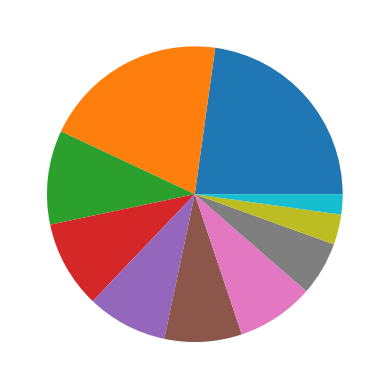

In [102]:
bins = pd.cut(df["waiting"], bins=10)


plt.pie(bins.value_counts(normalize=True))
plt.show()